# EfficientNet-B0 (Matthew Ico)

Train and evaluate a dental image classifier on 6 classes: calculus, caries, hypodontia, mouth ulcer, normal and tooth discoloration. The model is fine-tuned from an ImageNet-pretrained EfficientNet-B0.

**Flow:** find the dataset → settings and libraries → load and preview the images → build the model → train → evaluate and save results → Grad-CAM → predict an unseen image.

**Training:** the checkpoint with the best validation macro-F1 is kept as `best.pt`. The weights after epochs 2, 5 and 10 are also saved so the Grad-CAM heat maps can be compared across training.

**Outputs:** the test-set classification report, confusion matrices (raw counts and normalised by row), `metrics.json`, `split.csv`, the saved checkpoints, Grad-CAM figures and a `predict_image()` function for new photos.

Written to run on Kaggle with a GPU runtime. Run the cells from top to bottom.

## 1. Find the dataset

In [2]:
import os
from pathlib import Path

INPUT_DIR = Path('/kaggle/input')
WORK_DIR = Path('/kaggle/working')
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
N_CLASSES = 6

DATA_OVERRIDE = None

def find_dataset_root(base):
    for dirpath, dirnames, _ in os.walk(base):
        class_dirs = [d for d in dirnames
                      if any(Path(dirpath, d, f).suffix.lower() in IMG_EXT for f in os.listdir(Path(dirpath, d)))]
        if len(class_dirs) == N_CLASSES:
            return Path(dirpath)
    return None

DATA = Path(DATA_OVERRIDE) if DATA_OVERRIDE else find_dataset_root(INPUT_DIR)
assert DATA is not None and DATA.exists(), (
    f'Cannot find a folder with {N_CLASSES} class folders under {INPUT_DIR}. '
    'Add the dataset with "Add Input", or set DATA_OVERRIDE above.')
print('Dataset:', DATA)
for d in sorted(p for p in DATA.iterdir() if p.is_dir()):
    print(f'  {d.name:<22} {sum(1 for f in d.iterdir() if f.suffix.lower() in IMG_EXT):>5} images')

Dataset: /kaggle/input/datasets/matthewico/oraldataset/oral dataset
  Calculus                1296 images
  Hypodontia              1251 images
  Mouth ulcer              265 images
  Normal                   286 images
  caries                   219 images
  tooth discoloration     1058 images


## 2. Settings and libraries

In [ ]:
import json
import random
import csv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix, f1_score
from tqdm.auto import tqdm

MODEL = 'efficientnet_b0'
RUN_NAME = 'member_3_efficientnet'
EPOCHS = 10
BATCH_SIZE = 32
LEARNING_RATE = 0.0001
IMAGE_SIZE = 224
SEED = 42

VAL_FRAC = 0.15
TEST_FRAC = 0.15
GRADCAM_EPOCHS = [2, 5, 10]
GRADCAM_TARGET = 'pred'
assert max(GRADCAM_EPOCHS) <= EPOCHS, 'EPOCHS must be at least as large as the last Grad-CAM epoch'

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SAVE_DIR = WORK_DIR / 'models' / RUN_NAME
SNAP_DIR = SAVE_DIR / 'snapshots'
SNAP_DIR.mkdir(parents=True, exist_ok=True)
print('Device:', DEVICE, '| Model:', MODEL)

Device: cuda | Model: efficientnet_b0


## 3. Load and preview the images

The dataset is one folder per class with **no train / validation / test split**, so we make one. Each class is split **separately** (*stratified*) 70 / 15 / 15 with a fixed seed, so every class appears in all three sets in the same proportion and the split is identical on every run. The test set is never used for training or for choosing the epoch. The split is saved to `split.csv`.

Classes: ['Calculus', 'Hypodontia', 'Mouth ulcer', 'Normal', 'caries', 'tooth discoloration']
Images: 3061 train / 657 validation / 657 test


,train,val,test
Calculus,908,194,194
Hypodontia,875,188,188
Mouth ulcer,185,40,40
Normal,200,43,43
caries,153,33,33
tooth discoloration,740,159,159


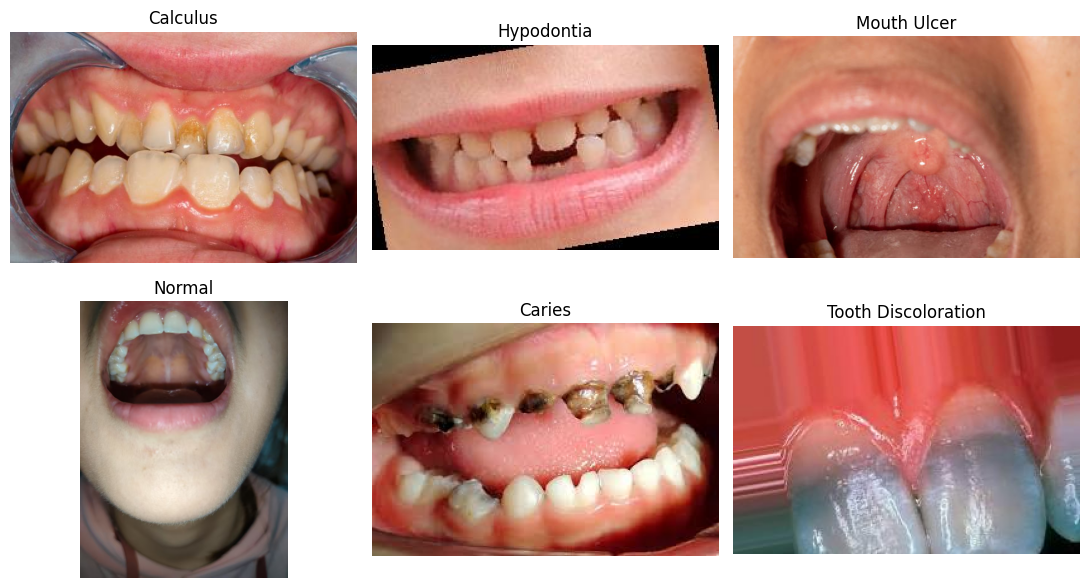

In [4]:
normalize = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_transform = transforms.Compose([
    transforms.Resize(256), transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomRotation(8),
    transforms.ColorJitter(brightness=0.12, contrast=0.12),
    transforms.ToTensor(), normalize,
])
val_transform = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(), normalize,
])

# Two views of the same folder: one with training augmentation, one with evaluation preprocessing.
full_train = datasets.ImageFolder(DATA, transform=train_transform)
full_eval = datasets.ImageFolder(DATA, transform=val_transform)
class_to_idx = full_eval.class_to_idx
names = full_eval.classes
pretty = lambda s: s.replace('_', ' ').title()

all_idx = np.arange(len(full_eval))
all_y = np.array(full_eval.targets)
trainval_idx, test_idx = train_test_split(all_idx, test_size=TEST_FRAC, stratify=all_y, random_state=SEED)
train_idx, val_idx = train_test_split(trainval_idx, test_size=VAL_FRAC / (1 - TEST_FRAC),
                                      stratify=all_y[trainval_idx], random_state=SEED)

class Split(Subset):
    # Subset that also exposes .samples and .targets, so the rest of the notebook works unchanged.
    def __init__(self, base, indices):
        super().__init__(base, indices)
        self.samples = [base.samples[i] for i in indices]
        self.targets = [base.targets[i] for i in indices]

train_data = Split(full_train, train_idx)
val_data = Split(full_eval, val_idx)
test_data = Split(full_eval, test_idx)

with open(SAVE_DIR / 'class_to_idx.json', 'w', encoding='utf-8') as f:
    json.dump(class_to_idx, f, indent=2)
pd.DataFrame([(p, names[y], s) for s, d in [('train', train_data), ('val', val_data), ('test', test_data)]
              for p, y in d.samples], columns=['path', 'class', 'split']).to_csv(SAVE_DIR / 'split.csv', index=False)

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, num_workers=2)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, num_workers=2)

print('Classes:', names)
print(f'Images: {len(train_data)} train / {len(val_data)} validation / {len(test_data)} test')
K = len(names)
display(pd.DataFrame({s: np.bincount(d.targets, minlength=K) for s, d in
                      [('train', train_data), ('val', val_data), ('test', test_data)]}, index=names))

fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, class_id in zip(axes.flat, range(len(names))):
    choices = [path for path, label in train_data.samples if label == class_id]
    with Image.open(random.choice(choices)) as image:
        ax.imshow(image.convert('RGB'))
    ax.set_title(pretty(names[class_id]))
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Build the model

In [5]:
def build_model(name, n_classes, pretrained=True):
    if name == 'resnet18':
        net = models.resnet18(weights=models.ResNet18_Weights.DEFAULT if pretrained else None)
        net.fc = nn.Linear(net.fc.in_features, n_classes)
    elif name == 'mobilenet_v3_small':
        net = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT if pretrained else None)
        net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, n_classes)
    elif name == 'efficientnet_b0':
        net = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, n_classes)
    elif name == 'custom_cnn':
        net = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3),
            nn.Linear(256, n_classes),
        )
    else:
        raise ValueError(f'Unknown model: {name}')
    return net

model = build_model(MODEL, len(names)).to(DEVICE)
counts = torch.bincount(torch.tensor(train_data.targets), minlength=len(names)).float()
weights = (counts.sum() / (len(names) * counts)).to(DEVICE)
loss_fn = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
print('Trainable parameters:', f'{sum(p.numel() for p in model.parameters() if p.requires_grad):,}')

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 152MB/s]


Trainable parameters: 4,015,234


## 5. Train

The model trains for `EPOCHS` epochs and the checkpoint with the best validation macro-F1 is kept as `best.pt`. In addition, the weights after epochs **2, 5 and 10** (`GRADCAM_EPOCHS`) are saved to `snapshots/`, so Step 7 can show how the model's Grad-CAM heat maps change as it trains.

  0%|          | 0/96 [00:00<?, ?it/s]

Epoch 01/10 | train loss 1.282 | val loss 0.694 | val F1 0.773


  0%|          | 0/96 [00:00<?, ?it/s]

Epoch 02/10 | train loss 0.547 | val loss 0.295 | val F1 0.901


  0%|          | 0/96 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dee4f3571a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dee4f3571a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (15 outputs left out)

Epoch 09/10 | train loss 0.087 | val loss 0.171 | val F1 0.944


  0%|          | 0/96 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dee4f3571a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dee4f3571a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 10/10 | train loss 0.070 | val loss 0.176 | val F1 0.963


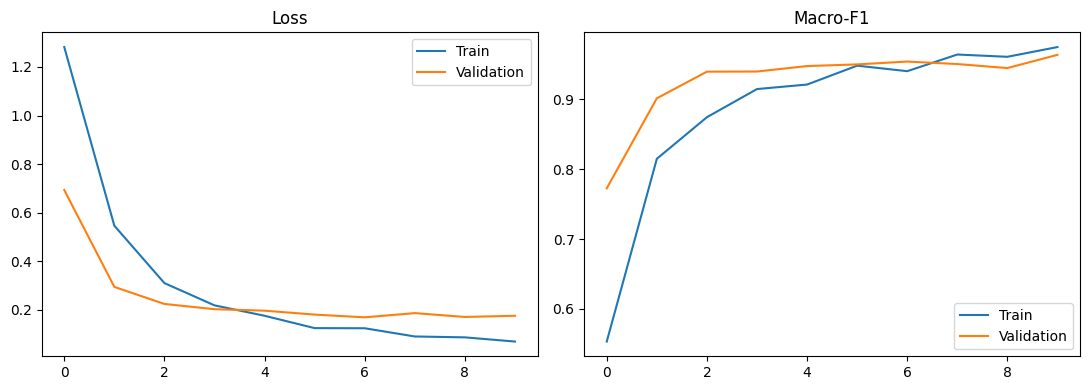

Best validation macro-F1 0.963 at epoch 10


In [6]:
def run_epoch(loader, training=False):
    model.train(training)
    total_loss = 0.0
    actual, predicted = [], []
    for images, labels in tqdm(loader, leave=False, disable=not training):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        with torch.set_grad_enabled(training):
            scores = model(images)
            loss = loss_fn(scores, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * len(labels)
        actual.extend(labels.cpu().tolist())
        predicted.extend(scores.argmax(1).cpu().tolist())
    return (total_loss / len(loader.dataset),
            f1_score(actual, predicted, average='macro', zero_division=0),
            actual, predicted)

best_f1 = -1
best_epoch = 0  # modified
history = []
CHECKPOINT = SAVE_DIR / 'best.pt'

for epoch in range(1, EPOCHS + 1):
    train_loss, train_f1, _, _ = run_epoch(train_loader, training=True)
    val_loss, val_f1, _, _ = run_epoch(val_loader)
    history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
                    'train_f1': train_f1, 'val_f1': val_f1})
    print(f'Epoch {epoch:02}/{EPOCHS} | train loss {train_loss:.3f} | val loss {val_loss:.3f} | val F1 {val_f1:.3f}')
    if val_f1 > best_f1:
        best_f1 = val_f1
        best_epoch = epoch  # modified
        torch.save({'state_dict': model.state_dict(), 'model_name': MODEL,
                    'class_to_idx': class_to_idx, 'image_size': IMAGE_SIZE,
                    'val_macro_f1': best_f1, 'epoch': epoch}, CHECKPOINT)
    if epoch in GRADCAM_EPOCHS:
        torch.save(model.state_dict(), SNAP_DIR / f'epoch_{epoch:02d}.pt')

with open(SAVE_DIR / 'history.csv', 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=history[0].keys())
    writer.writeheader()
    writer.writerows(history)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([x['train_loss'] for x in history], label='Train')
ax[0].plot([x['val_loss'] for x in history], label='Validation')
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot([x['train_f1'] for x in history], label='Train')
ax[1].plot([x['val_f1'] for x in history], label='Validation')
ax[1].set_title('Macro-F1'); ax[1].legend()
plt.tight_layout()
plt.savefig(SAVE_DIR / 'training_curves.png', dpi=140)
plt.show()
print(f'Best validation macro-F1 {best_f1:.3f} at epoch {best_epoch}')  # modified

## 6. Evaluate and save results



### Reading the results

The test set was not used for training or for choosing the epoch, so these numbers estimate performance on unseen images.

The confusion matrix is shown twice. **Left:** raw image counts. **Right:** *normalised by row*: each row is a true class divided by that class's number of images, so every row sums to 1. The diagonal is then the **recall** of each class and the off-diagonal cells show which classes are confused with which. Normalising makes small and large classes comparable, which raw counts do not.

Test loss: 0.198 | Accuracy: 0.960 | Macro-F1: 0.938
                     precision    recall  f1-score   support

           Calculus      0.954     0.959     0.956       194
         Hypodontia      0.979     0.979     0.979       188
        Mouth ulcer      0.907     0.975     0.940        40
             Normal      0.977     0.977     0.977        43
             caries      0.812     0.788     0.800        33
tooth discoloration      0.987     0.969     0.978       159

           accuracy                          0.960       657
          macro avg      0.936     0.941     0.938       657
       weighted avg      0.961     0.960     0.960       657



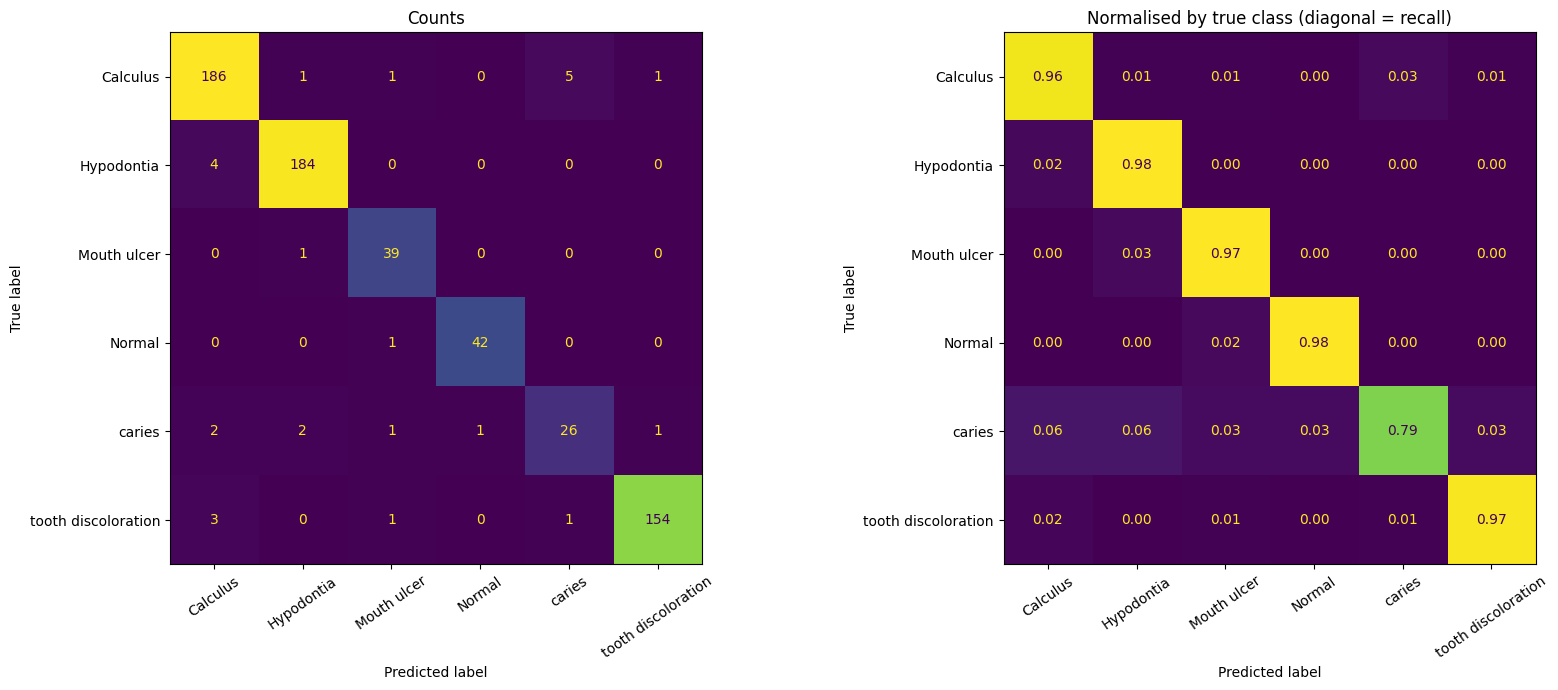

Saved results to: /kaggle/working/models/member_3_efficientnet


In [7]:
checkpoint = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint['state_dict'])
test_loss, test_f1, actual, predicted = run_epoch(test_loader)

test_acc = float((np.array(actual) == np.array(predicted)).mean())  # modified
print(f'Test loss: {test_loss:.3f} | Accuracy: {test_acc:.3f} | Macro-F1: {test_f1:.3f}')  # modified
print(classification_report(actual, predicted, target_names=names, digits=3, zero_division=0))

cm = confusion_matrix(actual, predicted, labels=range(len(names)))
fig, axes = plt.subplots(1, 2, figsize=(17, 7))  # modified: counts (left) and normalised (right)
ConfusionMatrixDisplay(cm, display_labels=names).plot(ax=axes[0], xticks_rotation=35, colorbar=False)
axes[0].set_title('Counts')  # modified
ConfusionMatrixDisplay.from_predictions(actual, predicted, labels=range(len(names)), display_labels=names,
                                        normalize='true', values_format='.2f', xticks_rotation=35,
                                        ax=axes[1], colorbar=False)  # modified: each row divided by its class total
axes[1].set_title('Normalised by true class (diagonal = recall)')  # modified
plt.tight_layout()
plt.savefig(SAVE_DIR / 'confusion_matrix.png', dpi=140)
plt.show()

metrics = {'model': MODEL, 'best_val_macro_f1': best_f1, 'test_macro_f1': test_f1,
           'test_loss': test_loss, 'test_accuracy': test_acc, 'classification_report': classification_report(
               actual, predicted, target_names=names, output_dict=True, zero_division=0)}
with open(SAVE_DIR / 'metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2)
print('Saved results to:', SAVE_DIR)

## 7. Grad-CAM

A high test score doesn't tell us the model is looking at the right thing. It might be using the background or a watermark instead of the teeth. Grad-CAM shows which parts of an image the model used for its prediction.

How it works:

1. Pass the image through the network and keep the feature maps of the last conv block (`features[-1]`, 1280 maps of 7x7).
2. Backpropagate from the class score to get the gradient of each feature map.
3. Average each gradient to get one weight per channel.
4. Take the weighted sum of the feature maps, then apply ReLU so only the evidence for the class is kept.
5. Upsample to the image size and overlay it as a heat map (red = most influence).

Instead of only looking at the final model, this step reloads the snapshots saved at epochs 2, 5 and 10 (Step 5) and runs them on the same test images. Reading a row left to right shows how the heat map changes as training goes on.

- Figure 1: one image per class, taken from the most confident correct predictions of the epoch 10 model.
- Figure 2: the most confident mistakes of the epoch 10 model.
- Each panel title shows the predicted class and confidence (green = correct, red = wrong). The map explains the predicted class by default. Set `GRADCAM_TARGET = 'true'` in Step 2 to explain the true class instead.

Each map is scaled to its own 0-1 range, so compare where the heat is, not how red it looks. The map is only 7x7 so it is coarse, and it shows what the model used, not whether that is medically correct.

,val_macro_f1,test_macro_f1,test_accuracy
epoch,,,
2,0.901,0.872,0.904
5,0.947,0.935,0.954
10,0.963,0.938,0.960


/tmp/ipykernel_50/2054333538.py:41: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  prob = float(logits.softmax(1)[0, pred])


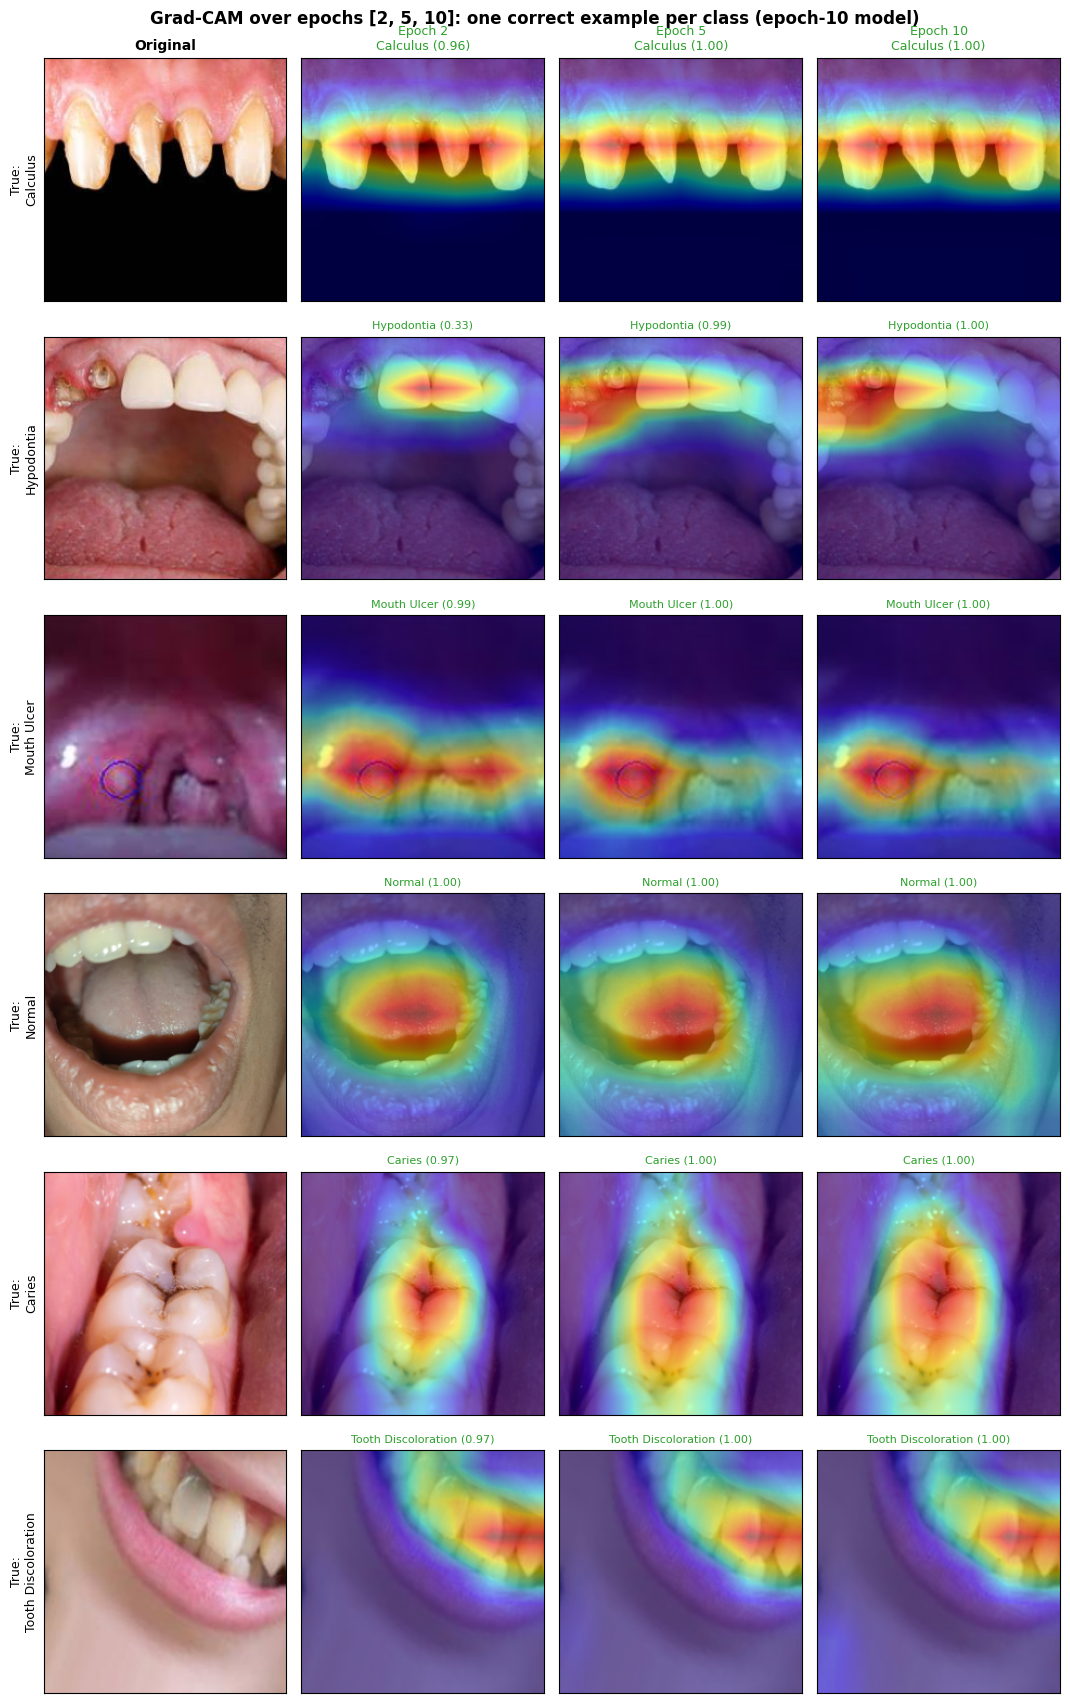

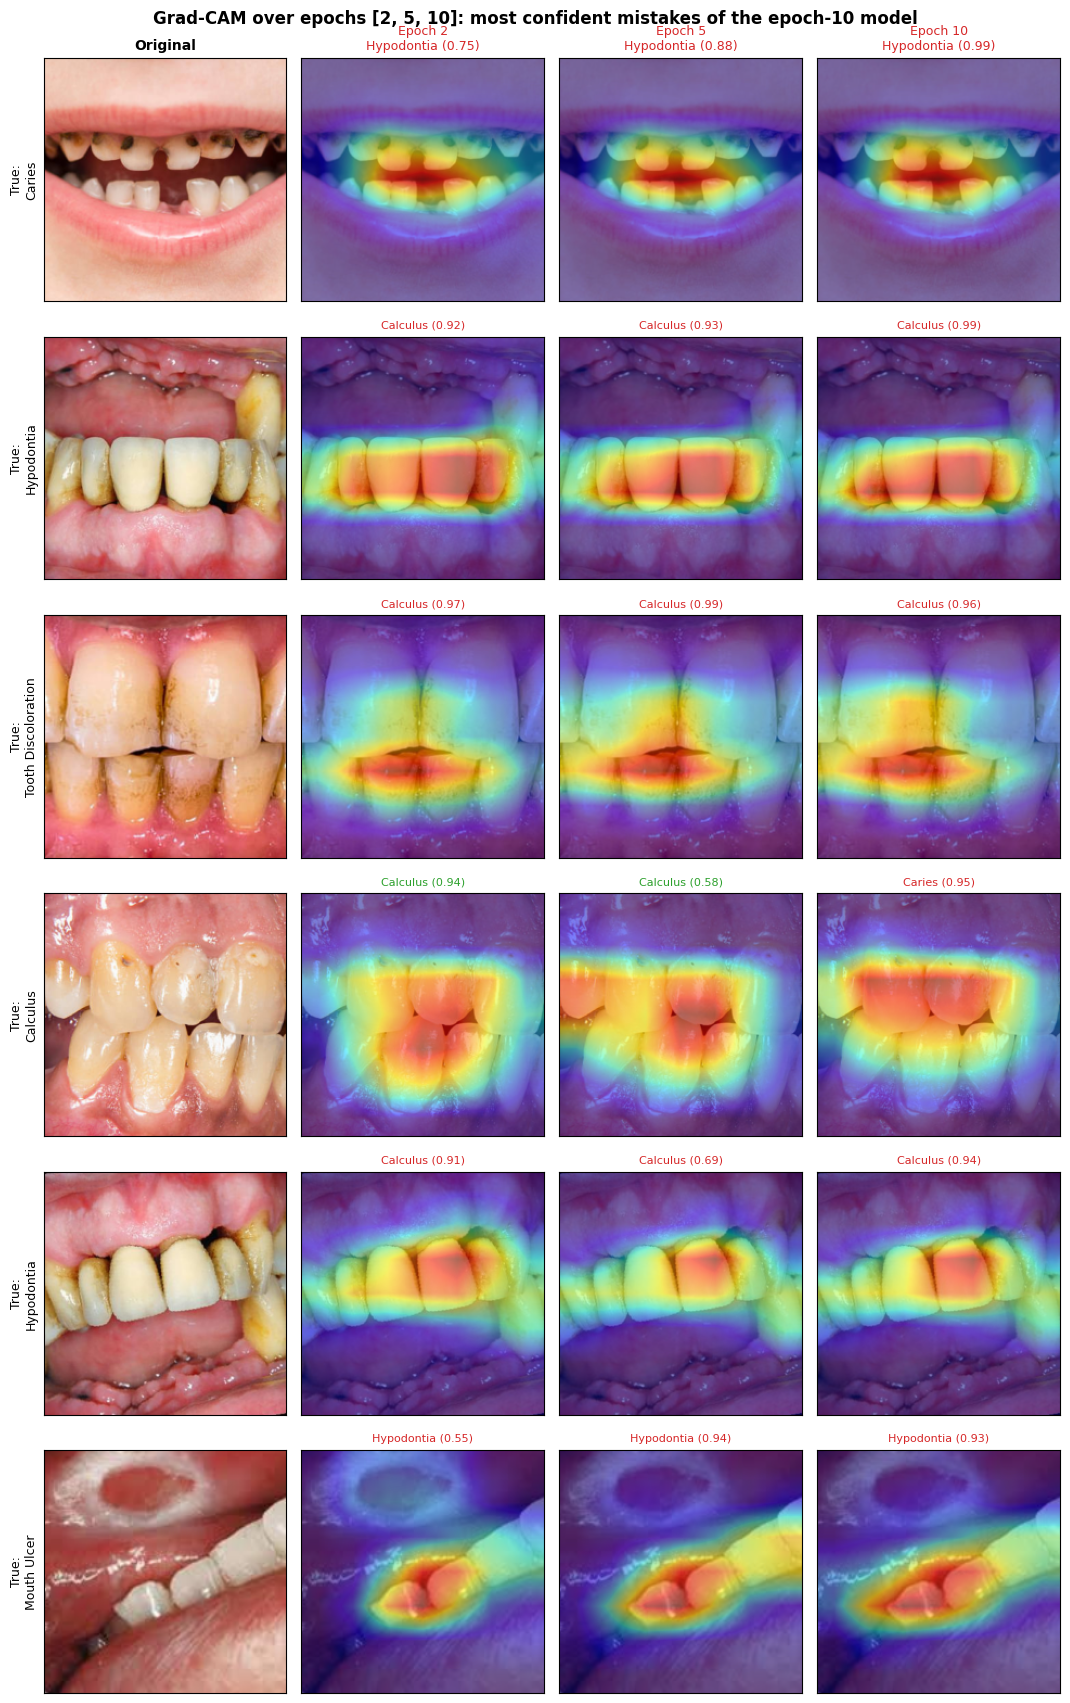

Epoch-10 test errors: 26 of 657 images


In [8]:
import torch.nn.functional as F

show_tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(IMAGE_SIZE)])

def load_snapshot(epoch):
    net = build_model(MODEL, len(names), pretrained=False).to(DEVICE)   # weights come from the snapshot, no download needed
    net.load_state_dict(torch.load(SNAP_DIR / f'epoch_{epoch:02d}.pt', map_location=DEVICE, weights_only=True))
    return net.eval()

@torch.no_grad()
def predict_loader(net, loader):
    net.eval()
    ys, ps, probs = [], [], []
    for images, labels in loader:
        out = net(images.to(DEVICE))
        probs.append(out.softmax(1).cpu())
        ps.extend(out.argmax(1).cpu().tolist())
        ys.extend(labels.tolist())
    return np.array(ys), np.array(ps), torch.cat(probs).numpy()

def gradcam_layer(net):
    if hasattr(net, 'features'):
        return net.features[-1]          # EfficientNet / MobileNet: last convolutional block
    if hasattr(net, 'layer4'):
        return net.layer4                # ResNet
    raise ValueError('Grad-CAM target layer is not defined for this model')

def grad_cam(net, x, class_idx=None):
    # x: [1, 3, H, W]. Returns (heat map 0-1 of size HxW, predicted class, probability of the predicted class).
    store = {}
    def fwd_hook(module, inputs, output):
        store['A'] = output
        output.register_hook(lambda grad: store.__setitem__('G', grad))   # gradient of the score w.r.t. the feature maps
    handle = gradcam_layer(net).register_forward_hook(fwd_hook)
    try:
        net.eval(); net.zero_grad()
        with torch.enable_grad():
            logits = net(x)
            pred = int(logits.argmax(1))
            prob = float(logits.softmax(1)[0, pred])
            logits[0, pred if class_idx is None else class_idx].backward()   # back-propagate from the class score
    finally:
        handle.remove()
    A, G = store['A'].detach()[0], store['G'][0]                         # [channels, h, w]
    alpha = G.mean(dim=(1, 2))                                           # one weight per channel
    cam = torch.relu((alpha[:, None, None] * A).sum(0))                  # weighted sum + ReLU
    cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.cpu().numpy(), pred, prob

def overlay(pil_img, cam, alpha=0.5):
    base = np.asarray(pil_img, dtype=np.float32) / 255.0
    return np.clip((1 - alpha) * base + alpha * plt.cm.jet(cam)[..., :3], 0, 1)

# Test-set score of each saved epoch (for the table and for choosing the images to show)
epoch_preds = {}
rows = []
for ep in GRADCAM_EPOCHS:
    y_ep, p_ep, pr_ep = predict_loader(load_snapshot(ep), test_loader)
    epoch_preds[ep] = (y_ep, p_ep, pr_ep)
    rows.append({'epoch': ep, 'val_macro_f1': history[ep - 1]['val_f1'],
                 'test_macro_f1': f1_score(y_ep, p_ep, average='macro', zero_division=0),
                 'test_accuracy': float((y_ep == p_ep).mean())})
display(pd.DataFrame(rows).set_index('epoch').round(3))

# Images are picked with the LAST snapshot, so the right-hand column matches the story of the final model
REF_EPOCH = max(GRADCAM_EPOCHS)
ref_y, ref_pred, ref_probs = epoch_preds[REF_EPOCH]

correct_idx = []
for c in range(len(names)):
    ids = np.where((ref_y == c) & (ref_pred == c))[0]
    if len(ids):
        correct_idx.append(int(ids[np.argmax(ref_probs[ids, c])]))      # most confident correct example of class c
wrong = np.where(ref_y != ref_pred)[0]
wrong_idx = [int(i) for i in wrong[np.argsort(-ref_probs[wrong, ref_pred[wrong]])][:len(names)]]   # most confident mistakes first

def gradcam_evolution(indices, title, filename):
    if len(indices) == 0:
        print(f'{title}: nothing to show'); return
    cols = 1 + len(GRADCAM_EPOCHS)
    results = {}
    for ep in GRADCAM_EPOCHS:                                           # one snapshot at a time to keep memory low
        net = load_snapshot(ep)
        for i in indices:
            x, label = test_data[i]                                     # same preprocessing as evaluation
            target = label if GRADCAM_TARGET == 'true' else None
            results[(ep, i)] = grad_cam(net, x.unsqueeze(0).to(DEVICE), target)
        del net
    fig, axes = plt.subplots(len(indices), cols, figsize=(2.7 * cols, 2.9 * len(indices)), squeeze=False)
    for r, i in enumerate(indices):
        path, true_id = test_data.samples[i]
        img = show_tf(Image.open(path).convert('RGB'))
        axes[r, 0].imshow(img)
        axes[r, 0].set_ylabel(f'True:\n{pretty(names[true_id])}', fontsize=9)
        for c, ep in enumerate(GRADCAM_EPOCHS, start=1):
            cam, pred, prob = results[(ep, i)]
            axes[r, c].imshow(overlay(img, cam))
            axes[r, c].set_title(f'{pretty(names[pred])} ({prob:.2f})', fontsize=8,
                                 color='tab:green' if pred == true_id else 'tab:red')
        for ax in axes[r]:
            ax.set_xticks([]); ax.set_yticks([])
    axes[0, 0].set_title('Original', fontsize=10, weight='bold')
    for c, ep in enumerate(GRADCAM_EPOCHS, start=1):
        axes[0, c].set_title(f'Epoch {ep}\n' + axes[0, c].get_title(), fontsize=9)
    fig.suptitle(title, fontsize=12, weight='bold')
    plt.tight_layout()
    plt.savefig(SAVE_DIR / filename, dpi=140)
    plt.show()

gradcam_evolution(correct_idx, f'Grad-CAM over epochs {GRADCAM_EPOCHS}: one correct example per class (epoch-{REF_EPOCH} model)',
                  'gradcam_evolution_correct.png')
gradcam_evolution(wrong_idx, f'Grad-CAM over epochs {GRADCAM_EPOCHS}: most confident mistakes of the epoch-{REF_EPOCH} model',
                  'gradcam_evolution_mistakes.png')
print(f'Epoch-{REF_EPOCH} test errors: {int((ref_y != ref_pred).sum())} of {len(ref_y)} images')

## 8. Predicting an unseen image

Loads the saved checkpoint and predicts on a new image, using the same preprocessing as validation and test (resize, centre crop, normalise). The class names are read from the checkpoint, and softmax turns the scores into probabilities. The top 3 are plotted.

To try your own photo, upload it to the notebook and call `predict_image('/kaggle/input/.../your_image.jpg')`. The cell below runs 3 random test images as a demo.

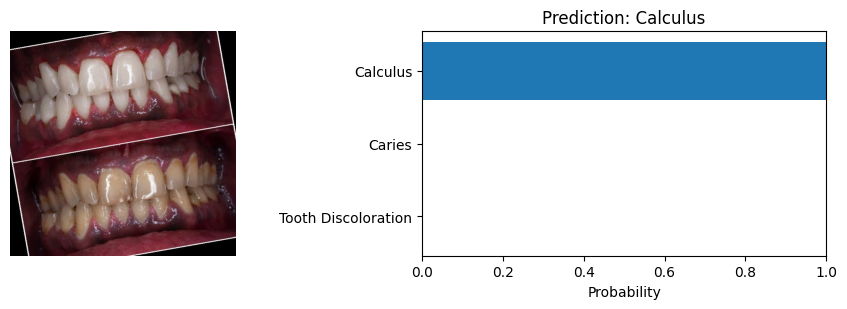

True class: Calculus | Predicted: Calculus (1.00)


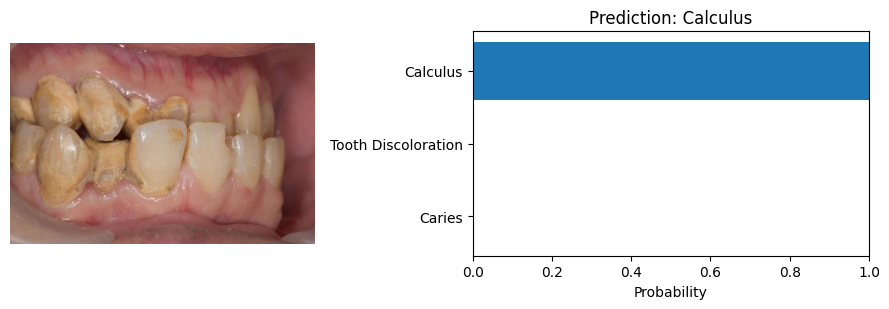

True class: Calculus | Predicted: Calculus (1.00)


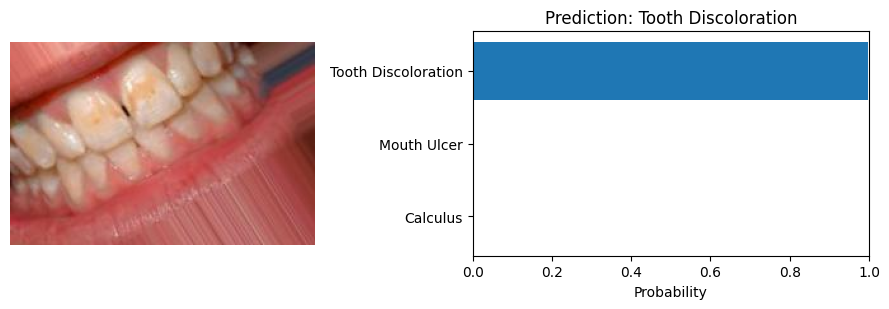

True class: Tooth Discoloration | Predicted: Tooth Discoloration (1.00)


In [9]:
def load_checkpoint(path):
    ckpt = torch.load(path, map_location=DEVICE, weights_only=True)
    net = build_model(ckpt['model_name'], len(ckpt['class_to_idx']), pretrained=False).to(DEVICE)
    net.load_state_dict(ckpt['state_dict'])
    net.eval()
    return net, ckpt

infer_net, infer_ckpt = load_checkpoint(CHECKPOINT)
idx_to_class = {v: k for k, v in infer_ckpt['class_to_idx'].items()}

def predict_image(path, net=infer_net, topk=3, show=True):
    img = Image.open(path).convert('RGB')
    x = val_transform(img).unsqueeze(0).to(DEVICE)
    net.eval()
    with torch.no_grad():
        probs = net(x).softmax(1)[0].cpu()
    top = probs.topk(topk)
    labels = [pretty(idx_to_class[i]) for i in top.indices.tolist()]
    if show:
        fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={'width_ratios': [1, 1.3]})
        ax[0].imshow(img); ax[0].axis('off')
        ax[1].barh(labels[::-1], top.values.tolist()[::-1], color='tab:blue')
        ax[1].set_xlim(0, 1); ax[1].set_xlabel('Probability'); ax[1].set_title(f'Prediction: {labels[0]}')
        plt.tight_layout(); plt.show()
    return labels[0], float(top.values[0])

demo_rng = random.Random(SEED + 1)
for path, true_id in demo_rng.sample(test_data.samples, 3):
    label, prob = predict_image(path)
    print(f"True class: {pretty(idx_to_class[true_id])} | Predicted: {label} ({prob:.2f})")